In [1]:
%pip install tensorflow numpy pandas matplotlib scikit-learn pillow


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.applications import MobileNetV2

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)


TensorFlow: 2.21.0
NumPy: 2.1.3


In [3]:

# Reproducibility
SEED = 123

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)


Random seed: 123


In [4]:
print("Available devices:")
for device in tf.config.list_physical_devices():
    print(device)


Available devices:
PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [5]:
from google.colab import files

uploaded = files.upload()

<IPython.core.display.HTML object>

Saving kaggle.json to kaggle (1).json


In [6]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json|

/bin/bash: -c: line 2: syntax error: unexpected end of file


In [7]:
!ls -l ~/.kaggle/

total 4
-rw-r--r-- 1 root root 71 Oct 22 07:04 kaggle.json


In [8]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
chest-xray-pneumonia.zip: Skipping, found more recently modified local copy (use --force to force download)


In [9]:
import zipfile
import os

zip_file = "chest-xray-pneumonia.zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("chest_xray")

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [10]:
for root, dirs, files in os.walk("chest_xray"):
    level = root.replace("chest_xray", "").count(os.sep)
    indent = " " * 4 * level
    print(indent + os.path.basename(root) + "/")

    if level < 3:
        for file in files[:5]:
            print(indent + "    " + file)

chest_xray/
    chest_xray/
        __MACOSX/
            ._chest_xray
            chest_xray/
                val/
                    NORMAL/
                    PNEUMONIA/
                test/
                    NORMAL/
                    PNEUMONIA/
                train/
                    NORMAL/
                    PNEUMONIA/
        chest_xray/
            .DS_Store
            val/
                NORMAL/
                PNEUMONIA/
            test/
                NORMAL/
                PNEUMONIA/
            train/
                NORMAL/
                PNEUMONIA/
        val/
            NORMAL/
            PNEUMONIA/
        test/
            NORMAL/
            PNEUMONIA/
        train/
            NORMAL/
            PNEUMONIA/


In [11]:
BASE_DIR = os.path.join("chest_xray", "chest_xray")

TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR = os.path.join(BASE_DIR, "val")
TEST_DIR = os.path.join(BASE_DIR, "test")

for path in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print(path, "->", os.path.exists(path))


chest_xray/chest_xray/train -> True
chest_xray/chest_xray/val -> True
chest_xray/chest_xray/test -> True


In [12]:

print("Training classes:", sorted(os.listdir(TRAIN_DIR)))
print("Validation classes:", sorted(os.listdir(VAL_DIR)))
print("Testing classes:", sorted(os.listdir(TEST_DIR)))


Training classes: ['NORMAL', 'PNEUMONIA']
Validation classes: ['NORMAL', 'PNEUMONIA']
Testing classes: ['NORMAL', 'PNEUMONIA']


In [13]:
def count_images(folder):
    counts = {}
    for class_name in ["NORMAL", "PNEUMONIA"]:
        class_path = os.path.join(folder, class_name)
        counts[class_name] = len([
            f for f in os.listdir(class_path)
            if os.path.isfile(os.path.join(class_path, f))
        ])
    return counts

train_counts = count_images(TRAIN_DIR)
val_counts = count_images(VAL_DIR)
test_counts = count_images(TEST_DIR)

distribution = pd.DataFrame({
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts
}).T

distribution


            NORMAL  PNEUMONIA
Train         1341       3875
Validation       8          8
Test           234        390

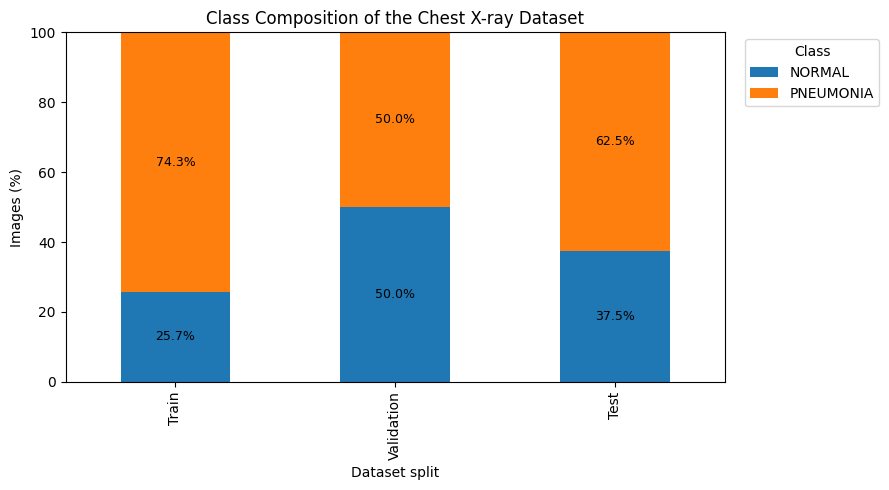

In [14]:



# this graph shows the percentage composition of each split.

percentage_distribution = distribution.div(
    distribution.sum(axis=1), axis=0
) * 100

ax = percentage_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

ax.set_title("Class Composition of the Chest X-ray Dataset")
ax.set_xlabel("Dataset split")
ax.set_ylabel("Images (%)")
ax.set_ylim(0, 100)
ax.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


In [15]:
#X-RAY IMAGES
normal_files = os.listdir(os.path.join(TRAIN_DIR, "NORMAL"))
pneumonia_files = os.listdir(os.path.join(TRAIN_DIR, "PNEUMONIA"))

print("Normal samples:", len(normal_files))
print("Pneumonia samples:", len(pneumonia_files))

Normal samples: 1341
Pneumonia samples: 3875


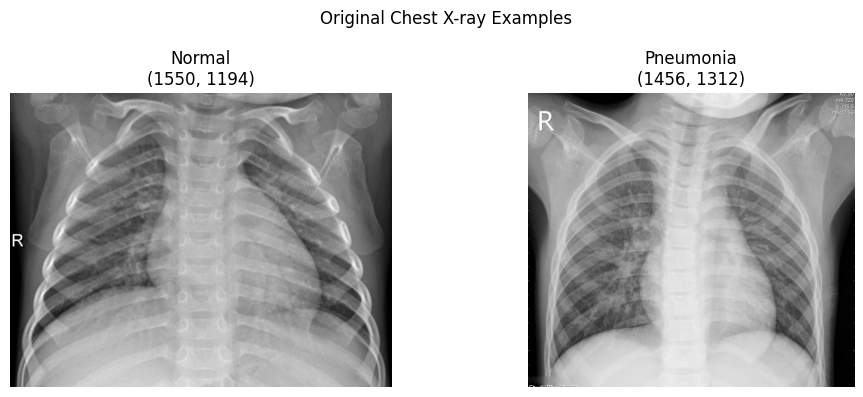

In [16]:
# one normal and one pneumonia image with their original dimensions.

normal_path = os.path.join(TRAIN_DIR, "NORMAL", normal_files[0])
pneumonia_path = os.path.join(TRAIN_DIR, "PNEUMONIA", pneumonia_files[0])

normal_img = Image.open(normal_path)
pneumonia_img = Image.open(pneumonia_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(normal_img, cmap="gray")
axes[0].set_title(f"Normal\n{normal_img.size}")
axes[0].axis("off")

axes[1].imshow(pneumonia_img, cmap="gray")
axes[1].set_title(f"Pneumonia\n{pneumonia_img.size}")
axes[1].axis("off")

fig.suptitle("Original Chest X-ray Examples")
plt.tight_layout()
plt.show()


In [17]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Class order:", class_names)


Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Class order: ['NORMAL', 'PNEUMONIA']


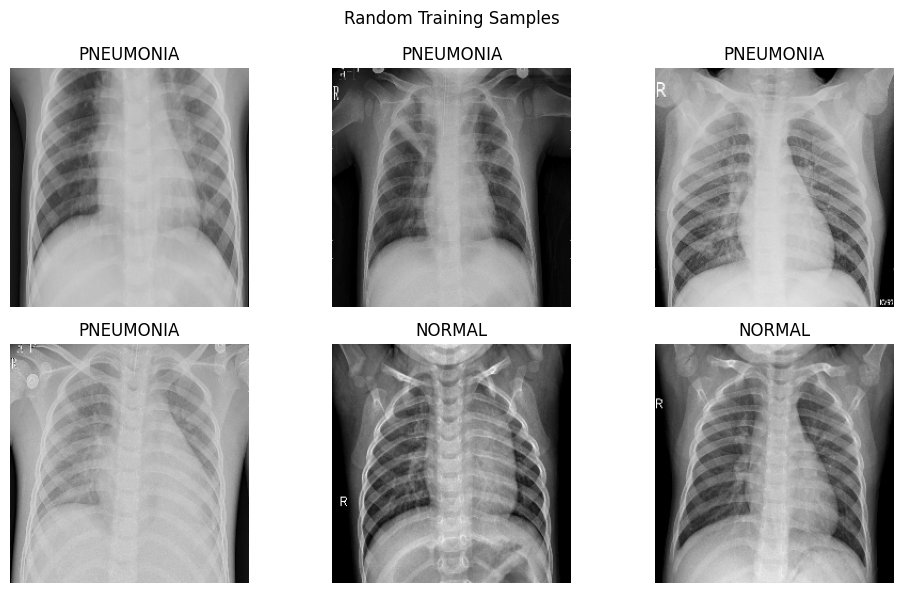

In [18]:
#  small batch using a different 2 x 3 layout.

images, labels = next(iter(train_ds))

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for ax, image, label in zip(axes.flat, images[:6], labels[:6]):
    ax.imshow(image.numpy().astype("uint8"))
    ax.set_title(class_names[int(label.numpy()[0])])
    ax.axis("off")

fig.suptitle("Random Training Samples")
plt.tight_layout()
plt.show()


In [19]:
#PREPROCESSING AND DATA AGUMENTATION
# Augmentation applied only to the training images.

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(height_factor=(-0.08, 0.08), width_factor=(-0.08, 0.08)),
    layers.RandomContrast(0.12)
], name="xray_augmentation")



In [20]:
# Faster input pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)


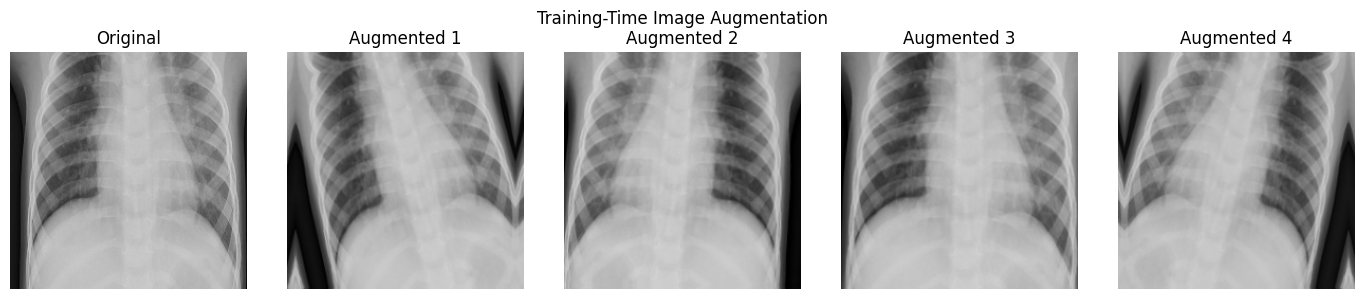

In [21]:
# Visualize augmentation effects on one image.

sample = images[0]

fig, axes = plt.subplots(1, 5, figsize=(14, 3))

axes[0].imshow(sample.numpy().astype("uint8"))
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(1, 5):
    changed = augmentation(tf.expand_dims(sample, 0), training=True)[0]
    axes[i].imshow(changed.numpy().astype("uint8"))
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")

plt.suptitle("Training-Time Image Augmentation")
plt.tight_layout()
plt.show()

In [22]:
cnn_model = Sequential([
    layers.Input(shape=(224, 224, 3)),

    augmentation,
    layers.Rescaling(1.0 / 255),

    # Block 1
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    # Block 2
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    # Block 3
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    # Block 4
    layers.Conv2D(192, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(1, activation="sigmoid")
], name="custom_xray_cnn")

cnn_model.summary()


Model: "custom_xray_cnn"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │

 Total params: 492,737 (1.88 MB)


 Trainable params: 491,905 (1.88 MB)


 Non-trainable params: 832 (3.25 KB)


In [23]:
#compile cnn
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-4),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

cnn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.4,
        patience=2,
        min_lr=1e-7
    ),
    keras.callbacks.ModelCheckpoint(
        "custom_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]


In [24]:
#Training CNN
cnn_epochs= 18

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=cnn_epochs,
    callbacks=cnn_callbacks
)


Epoch 1/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 42s 192ms/step - accuracy: 0.8639 - loss: 0.3049 - precision: 0.9032 - recall: 0.9148 - val_accuracy: 0.5000 - val_loss: 2.7391 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 2.0000e-04
Epoch 2/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 32s 194ms/step - accuracy: 0.9174 - loss: 0.2171 - precision: 0.9468 - recall: 0.9417 - val_accuracy: 0.5000 - val_loss: 3.7169 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 2.0000e-04
Epoch 3/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 189ms/step - accuracy: 0.9365 - loss: 0.1825 - precision: 0.9593 - recall: 0.9551 - val_accuracy: 0.5000 - val_loss: 3.4301 - val_precision: 0.5000 - val_recall: 1.0000 - learning_rate: 2.0000e-04
Epoch 4/18
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 190ms/step - accuracy: 0.9519 - loss: 0.1388 - precision: 0.9675 - recall: 0.9677 - val_accuracy: 0.6250 - val_loss: 0.8463 - val_precision: 0.5714 - val_recall: 1.0000 - learning_rate: 8.0000e-05
Epoch 5/18
163/163 ━━━━━━━━━━━━━━━━━

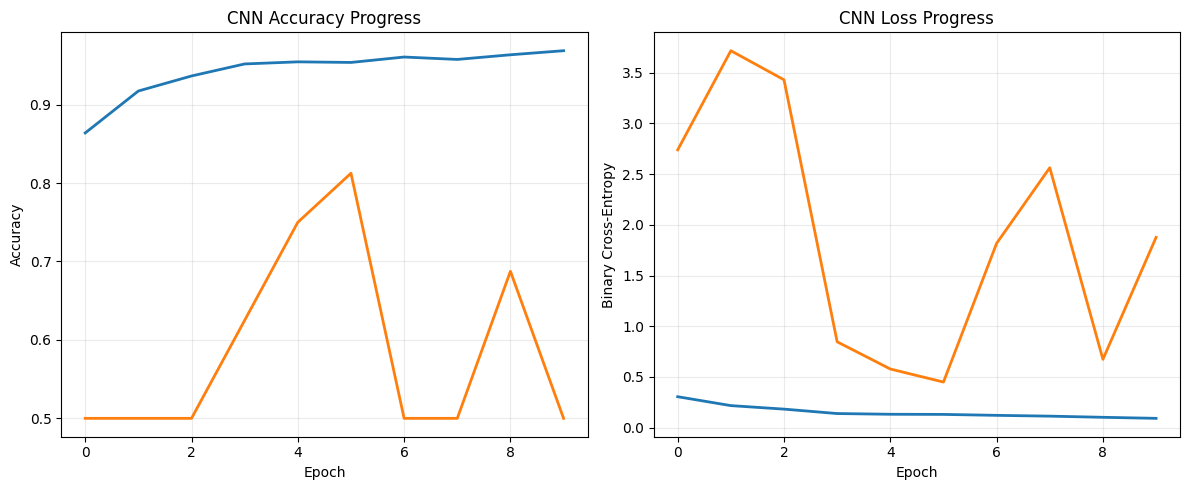

In [25]:
# Different graph presentation: two separate panels for accuracy and loss.
plt.figure(figsize=(12, 5))

# CNN Accuracy
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['accuracy'], linewidth=2)
plt.plot(cnn_history.history['val_accuracy'], linewidth=2)
plt.title("CNN Accuracy Progress")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(alpha=0.25)

# CNN Loss
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['loss'], linewidth=2)
plt.plot(cnn_history.history['val_loss'], linewidth=2)
plt.title("CNN Loss Progress")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [26]:
#CNN EVALUATION
cnn_test = cnn_model.evaluate(test_ds, return_dict=True)

print("Custom CNN test performance")
for name, value in cnn_test.items():
    print(f"{name.capitalize():10s}: {value:.4f}")


20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 133ms/step - accuracy: 0.8413 - loss: 0.3576 - precision: 0.9450 - recall: 0.7923
Custom CNN test performance
Accuracy  : 0.8413
Loss      : 0.3576
Precision : 0.9450
Recall    : 0.7923


In [27]:
#CNN CLASSIFICATION
def collect_predictions(model, dataset):
    y_true = []
    y_prob = []

    for batch_images, batch_labels in dataset:
        probabilities = model.predict(batch_images, verbose=0).ravel()
        y_prob.extend(probabilities)
        y_true.extend(batch_labels.numpy().ravel())

    y_true = np.array(y_true).astype(int)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= 0.5).astype(int)

    return y_true, y_prob, y_pred

cnn_true, cnn_prob, cnn_pred = collect_predictions(cnn_model, test_ds)

print(
    classification_report(
        cnn_true,
        cnn_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        digits=4
    )
)


              precision    recall  f1-score   support

      NORMAL     0.7273    0.9231    0.8136       234
   PNEUMONIA     0.9450    0.7923    0.8619       390

    accuracy                         0.8413       624
   macro avg     0.8361    0.8577    0.8377       624
weighted avg     0.8633    0.8413    0.8438       624



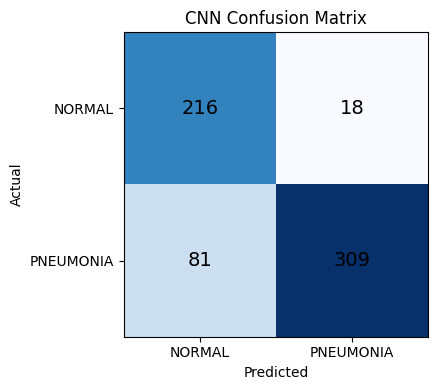

In [28]:

# Custom confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cnn_cm = confusion_matrix(cnn_true, cnn_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cnn_cm, cmap="Blues")

plt.xticks([0, 1], ["NORMAL", "PNEUMONIA"])
plt.yticks([0, 1], ["NORMAL", "PNEUMONIA"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cnn_cm[i, j],
                 ha="center", va="center", fontsize=14)

plt.tight_layout()
plt.show()

In [29]:
#Transfer Learning
from tensorflow.keras.applications import MobileNetV2

In [30]:
#Load and freeze MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

In [31]:
#Create the transfer-learning model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

transfer_model = tf.keras.Model(inputs, outputs)

transfer_model.summary()

Model: "functional_2"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤

 Total params: 2,340,033 (8.93 MB)


 Trainable params: 82,049 (320.50 KB)


 Non-trainable params: 2,257,984 (8.61 MB)


In [32]:
transfer_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.4,
        patience=2,
        min_lr=1e-7
    ),
    keras.callbacks.ModelCheckpoint(
        "mobilenet_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [33]:
#compile
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [34]:
mobilenet_train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.2,
    subset="training",
    seed=123
)

mobilenet_val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.2,
    subset="validation",
    seed=123
)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.


In [35]:
transfer_history = transfer_model.fit(
    mobilenet_train_ds,
    validation_data=mobilenet_val_ds,
    epochs=14,
    callbacks=transfer_callbacks
)

Epoch 1/14
131/131 ━━━━━━━━━━━━━━━━━━━━ 54s 323ms/step - accuracy: 0.8169 - loss: 0.4095 - precision: 0.8401 - recall: 0.9272 - val_accuracy: 0.9060 - val_loss: 0.2422 - val_precision: 0.9472 - val_recall: 0.9309 - learning_rate: 1.0000e-04
Epoch 2/14
131/131 ━━━━━━━━━━━━━━━━━━━━ 61s 223ms/step - accuracy: 0.8941 - loss: 0.2553 - precision: 0.9251 - recall: 0.9312 - val_accuracy: 0.9156 - val_loss: 0.2085 - val_precision: 0.9605 - val_recall: 0.9296 - learning_rate: 1.0000e-04
Epoch 3/14
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 259ms/step - accuracy: 0.9080 - loss: 0.2231 - precision: 0.9371 - recall: 0.9377 - val_accuracy: 0.9243 - val_loss: 0.1957 - val_precision: 0.9656 - val_recall: 0.9358 - learning_rate: 1.0000e-04
Epoch 4/14
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 259ms/step - accuracy: 0.9154 - loss: 0.2076 - precision: 0.9414 - recall: 0.9436 - val_accuracy: 0.9291 - val_loss: 0.1836 - val_precision: 0.9658 - val_recall: 0.9420 - learning_rate: 1.0000e-04
Epoch 5/14
131/131 ━━━━━━━━━━━━━━━━━

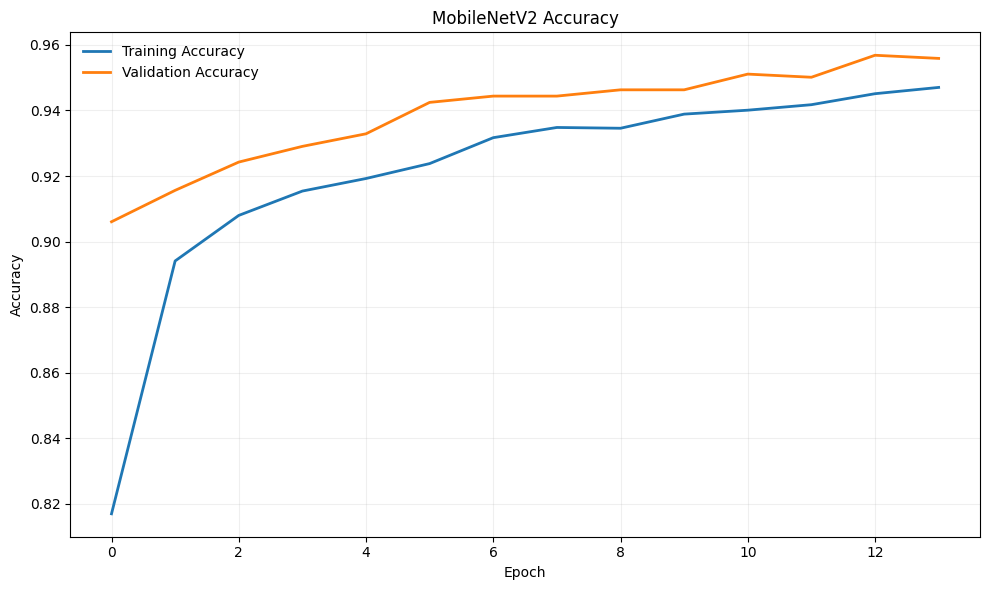

In [36]:
plt.figure(figsize=(10, 6))

plt.plot(
    transfer_history.history["accuracy"],
    linewidth=2
)

plt.plot(
    transfer_history.history["val_accuracy"],
    linewidth=2
)

plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(
    ["Training Accuracy", "Validation Accuracy"],
    frameon=False
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

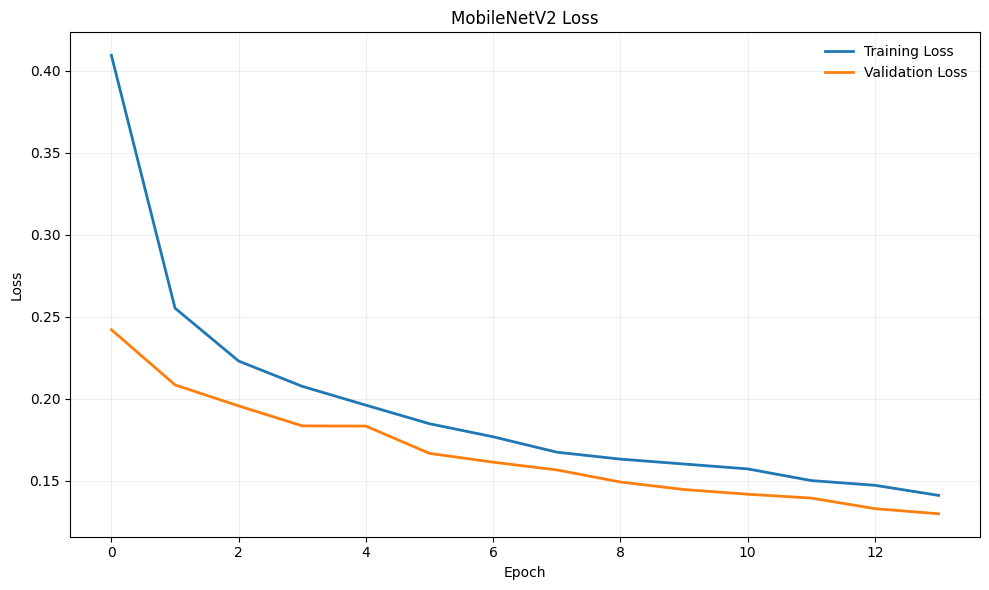

In [37]:
# MobileNetV2 Loss

plt.figure(figsize=(10, 6))

plt.plot(
    transfer_history.history["loss"],
    linewidth=2
)

plt.plot(
    transfer_history.history["val_loss"],
    linewidth=2
)

plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend(
    ["Training Loss", "Validation Loss"],
    frameon=False
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [38]:
#MobileNetV2 Test
# Test MobileNetV2

test_loss, test_accuracy, test_precision, test_recall = transfer_model.evaluate(test_ds)

print("MobileNetV2 Test Accuracy:", test_accuracy)
print("MobileNetV2 Test Precision:", test_precision)
print("MobileNetV2 Test Recall:", test_recall)

20/20 ━━━━━━━━━━━━━━━━━━━━ 11s 575ms/step - accuracy: 0.7692 - loss: 0.5920 - precision: 0.7347 - recall: 0.9872
MobileNetV2 Test Accuracy: 0.7692307829856873
MobileNetV2 Test Precision: 0.7347328066825867
MobileNetV2 Test Recall: 0.9871794581413269


20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 253ms/step


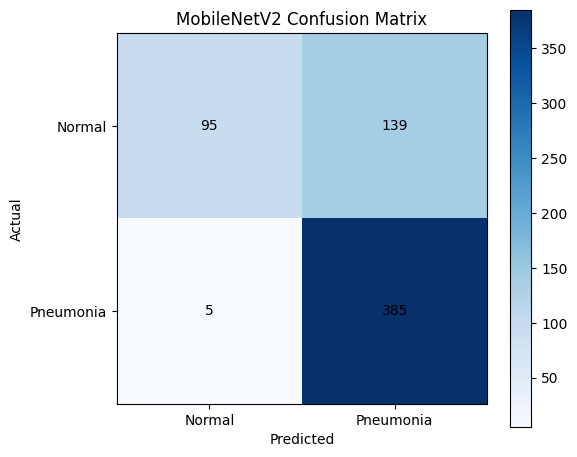

In [39]:
#Confusion Matrix
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Predictions
mobilenet_pred_prob = transfer_model.predict(test_ds)
mobilenet_pred = (mobilenet_pred_prob > 0.5).astype(int).flatten()

# True labels
mobilenet_true = np.concatenate([y.numpy() for x, y in test_ds]).astype(int)

# Confusion matrix
mobilenet_cm = confusion_matrix(mobilenet_true, mobilenet_pred)

# Plot
plt.figure(figsize=(6, 5))
plt.imshow(mobilenet_cm, cmap="Blues")

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Normal", "Pneumonia"])
plt.yticks([0, 1], ["Normal", "Pneumonia"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, mobilenet_cm[i, j],
                 ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

In [40]:
#MobileNetV2 classification report
print(classification_report(mobilenet_true, mobilenet_pred,
      target_names=["NORMAL", "PNEUMONIA"], digits=4))

              precision    recall  f1-score   support

      NORMAL     0.9500    0.4060    0.5689       234
   PNEUMONIA     0.7347    0.9872    0.8425       390

    accuracy                         0.7692       624
   macro avg     0.8424    0.6966    0.7057       624
weighted avg     0.8155    0.7692    0.7399       624



In [41]:
#Unfreeze for fine-tuning
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False

In [42]:
#Recompile
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy",
             tf.keras.metrics.Precision(name="precision"),
             tf.keras.metrics.Recall(name="recall")]
)

In [43]:
#Fine-tune
fine_tune_history = transfer_model.fit(
    mobilenet_train_ds,
    validation_data=mobilenet_val_ds,
    epochs=10,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=2, min_lr=1e-8)
    ]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 73s 363ms/step - accuracy: 0.8840 - loss: 0.2805 - precision: 0.9059 - recall: 0.9396 - val_accuracy: 0.9482 - val_loss: 0.1414 - val_precision: 0.9565 - val_recall: 0.9778 - learning_rate: 1.0000e-05
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 50s 220ms/step - accuracy: 0.9413 - loss: 0.1572 - precision: 0.9602 - recall: 0.9599 - val_accuracy: 0.9156 - val_loss: 0.1954 - val_precision: 0.9084 - val_recall: 0.9914 - learning_rate: 1.0000e-05
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 217ms/step - accuracy: 0.9578 - loss: 0.1161 - precision: 0.9731 - recall: 0.9693 - val_accuracy: 0.8763 - val_loss: 0.2973 - val_precision: 0.8657 - val_recall: 0.9951 - learning_rate: 1.0000e-05
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 28s 217ms/step - accuracy: 0.9710 - loss: 0.0841 - precision: 0.9826 - recall: 0.9778 - val_accuracy: 0.8677 - val_loss: 0.3279 - val_precision: 0.8574 - val_recall: 0.9951 - learning_rate: 2.0000e-06


In [44]:
#Evaluate fine-tuned model
loss, acc, prec, rec = transfer_model.evaluate(test_ds)
print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 247ms/step - accuracy: 0.7196 - loss: 0.7894 - precision: 0.6944 - recall: 0.9846
Accuracy : 0.7195512652397156
Precision: 0.6943942308425903
Recall   : 0.9846153855323792


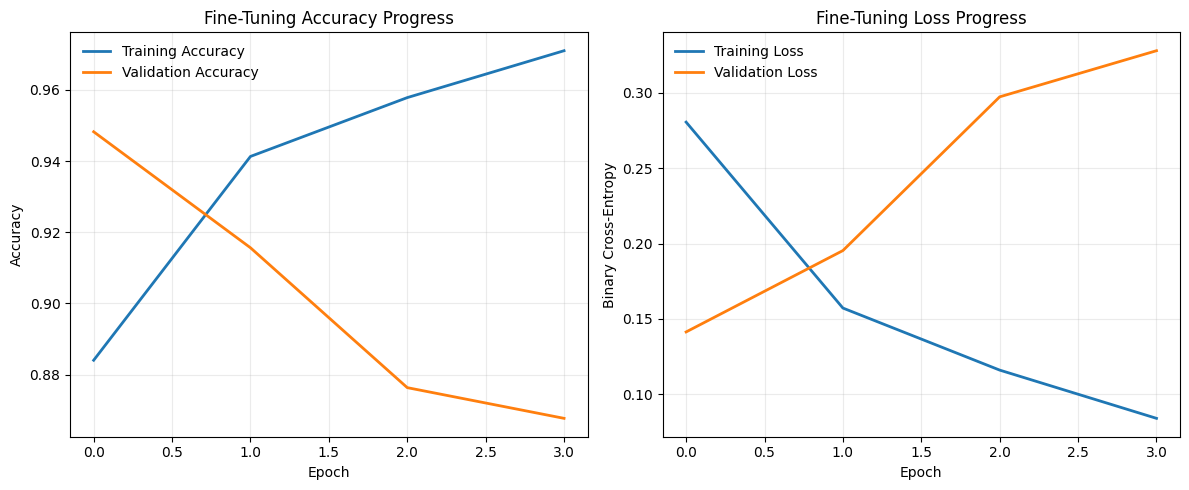

In [45]:
# Fine-tuning graphs (same style as the CNN graphs)
plt.figure(figsize=(12, 5))

# Fine-tuning accuracy
plt.subplot(1, 2, 1)
plt.plot(fine_tune_history.history['accuracy'], linewidth=2)
plt.plot(fine_tune_history.history['val_accuracy'], linewidth=2)
plt.title("Fine-Tuning Accuracy Progress")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Training Accuracy", "Validation Accuracy"], frameon=False)
plt.grid(alpha=0.25)
# Fine-tuning loss
plt.subplot(1, 2, 2)
plt.plot(fine_tune_history.history['loss'], linewidth=2)
plt.plot(fine_tune_history.history['val_loss'], linewidth=2)
plt.title("Fine-Tuning Loss Progress")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.legend(["Training Loss", "Validation Loss"], frameon=False)
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [46]:
#Fine-tuned classification report
ft_true, ft_prob, ft_pred = collect_predictions(transfer_model, test_ds)

print(classification_report(ft_true, ft_pred,
      target_names=["NORMAL", "PNEUMONIA"], digits=4))

              precision    recall  f1-score   support

      NORMAL     0.9155    0.2778    0.4262       234
   PNEUMONIA     0.6944    0.9846    0.8144       390

    accuracy                         0.7196       624
   macro avg     0.8049    0.6312    0.6203       624
weighted avg     0.7773    0.7196    0.6688       624



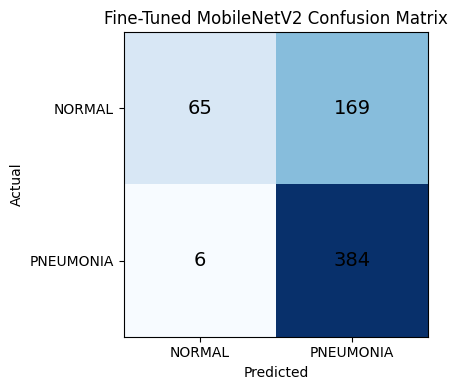

In [47]:
#Fine-tuned confusion matrix
cm = confusion_matrix(ft_true, ft_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], ["NORMAL", "PNEUMONIA"])
plt.yticks([0, 1], ["NORMAL", "PNEUMONIA"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fine-Tuned MobileNetV2 Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)

plt.tight_layout()
plt.show()

In [48]:
#save the model
transfer_model.save("pneumonia_mobilenetv2_final.keras")
loaded_model = tf.keras.models.load_model("pneumonia_mobilenetv2_final.keras")
loaded_model.evaluate(test_ds)

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 204ms/step - accuracy: 0.7196 - loss: 0.7894 - precision: 0.6944 - recall: 0.9846


[0.7893514633178711,
 0.7195512652397156,
 0.6943942308425903,
 0.9846153855323792]

In [49]:
#Prediction function
def predict_pneumonia(image_path, model):
    img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0][0]

    if prediction >= 0.5:
        return "PNEUMONIA", prediction
    else:
        return "NORMAL", 1 - prediction

In [50]:
#Upload a new X-ray
from google.colab import files

uploaded = files.upload()

<IPython.core.display.HTML object>

Saving images-2.jpeg to images-2 (1).jpeg


In [51]:
#Predict with the CNN
uploaded_files = list(uploaded.keys())

if uploaded_files:
    image_path = uploaded_files[-1]
    print(f"Processing most recent upload: {image_path}")

    predicted_class, confidence = predict_pneumonia(image_path, cnn_model)

    print("Prediction:", predicted_class)
    print(f"Confidence: {confidence * 100:.2f}%")
else:
    print("No files uploaded yet. Please upload an image first.")

Processing most recent upload: images-2 (1).jpeg
Prediction: PNEUMONIA
Confidence: 66.78%


In [52]:
import tensorflow as tf


try:
    best_mobilenet = tf.keras.models.load_model('mobilenet_best.keras')
    print("Loaded best MobileNetV2 model successfully.")
except Exception as e:
    best_mobilenet = transfer_model
    print("Using current transfer_model instead.")

def predict_ensemble(image_path):
    img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, axis=0)

    # Get predictions from both models
    pred_cnn = cnn_model.predict(img_array, verbose=0)[0][0]
    pred_mobilenet = best_mobilenet.predict(img_array, verbose=0)[0][0]


    ensemble_pred = (pred_cnn + pred_mobilenet) / 2.0

    if ensemble_pred >= 0.5:
        predicted_class = "PNEUMONIA"
        confidence = ensemble_pred
    else:
        predicted_class = "NORMAL"
        confidence = 1.0 - ensemble_pred

    print(f"[CNN Pred: {pred_cnn:.4f} | MobileNet Pred: {pred_mobilenet:.4f}]")
    return predicted_class, confidence

if uploaded_files:
    image_path = uploaded_files[-1]
    predicted_class, confidence = predict_ensemble(image_path)
    print(f"Ensemble Prediction: {predicted_class}")
    print(f"Ensemble Confidence: {confidence * 100:.2f}%")

Loaded best MobileNetV2 model successfully.
[CNN Pred: 0.6678 | MobileNet Pred: 0.9897]
Ensemble Prediction: PNEUMONIA
Ensemble Confidence: 82.87%


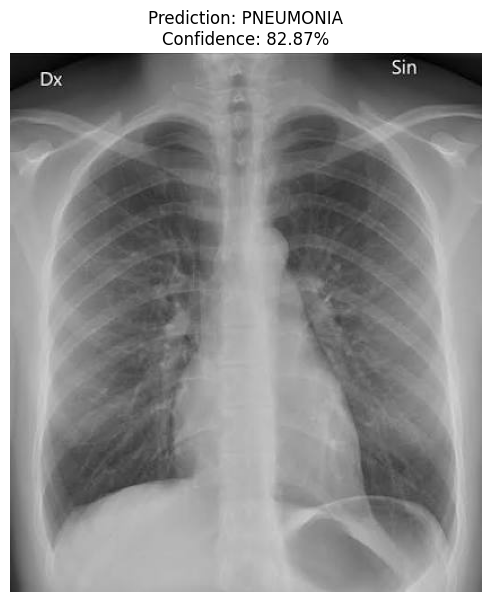

In [53]:
#Display X-Ray with prediction
img = Image.open(image_path)

plt.figure(figsize=(7, 7))

plt.imshow(img, cmap="gray")

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%"
)

plt.axis("off")
plt.show()

In [54]:
#Save the final model
transfer_model.save(
    "pneumonia_mobilenetv2_final.keras"
)

print("Model saved successfully!")

Model saved successfully!


In [55]:
#Load the saved model
loaded_model = tf.keras.models.load_model(
    "pneumonia_mobilenetv2_final.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


In [56]:
#evaluate model
loaded_model.evaluate(test_ds)

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 203ms/step - accuracy: 0.7196 - loss: 0.7894 - precision: 0.6944 - recall: 0.9846


[0.7893514633178711,
 0.7195512652397156,
 0.6943942308425903,
 0.9846153855323792]